# Comparações candidatas a artigo — `conjunto_alex` (metadados corrigidos)

Cada comparação é avaliada com as **mesmas métricas**, para poderem ser ranqueadas:

| métrica | o que mede |
|---|---|
| `R2`, `p_perm` | PERMANOVA (Bray–Curtis, ASV rarefeito): quanto da variação da comunidade o contraste explica |
| `g_Shannon`, `pct_Riqueza` | tamanho do efeito na diversidade alfa (Hedges g; % de mudança na riqueza mediana) |
| `n_generos_q05` | nº de gêneros com abundância diferencial (CLR + Mann‑Whitney, FDR < 5 %) |
| `p_disp` | diferença de dispersão entre grupos (PERMDISP); p baixo = parte do R² pode ser heterogeneidade |
| replicação | em quantos sítios/estudos independentes o efeito se repete |

Todas as 553 amostras entram aqui (inclusive intestino e culturas de enriquecimento).
O ranking final (seção 14) soma notas de 0–3 para **efeito**, **replicação/n**, **limpeza do desenho** e **novidade**.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from skbio.stats.ordination import pcoa
from util_analise import *

sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110; plt.rcParams['savefig.bbox'] = 'tight'
FIG, TAB = Path('figuras/v2'), Path('tabelas/v2'); FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / f'{name}.png', dpi=150); plt.show()

asv, tax, tree, meta, rare, alpha, gcounts = carregar()
A = alpha.join(meta)
RES, DA_TAB = [], {}
def registra(cid, nome, a, b, **kw):
    r, d = resumo_contraste(nome, a, b, rare, alpha, gcounts, meta=meta, **kw)
    r['id'] = cid; RES.append(r); DA_TAB[(cid, nome)] = d
    return r, d

def pcoa_plot(samples, hue, style=None, ax=None, title=''):
    o = pcoa(dist(rare, samples), number_of_dimensions=2)
    d = o.samples.set_axis(['PC1', 'PC2'], axis=1).join(meta)
    sns.scatterplot(data=d, x='PC1', y='PC2', hue=hue, style=style, ax=ax, s=40, palette='tab10')
    pe = o.proportion_explained.values[:2] * 100
    ax.set_xlabel(f'PC1 ({pe[0]:.0f}%)'); ax.set_ylabel(f'PC2 ({pe[1]:.0f}%)'); ax.set_title(title, fontsize=10); ax.legend(fontsize=6)

S = lambda q: list(meta.query(q).index)
print(meta.groupby(['BIOPROJECT', 'COMPARTIMENTO']).size().unstack(fill_value=0))

COMPARTIMENTO  Enriquecimento  Intestino  Plastisfera  Rizosfera  Solo
BIOPROJECT                                                            
PRJEB59875                  0          0            0         25     0
PRJNA1021161                0          0            0          0   111
PRJNA1054347                0          0            0         18    18
PRJNA1155845                0         24            0          0    24
PRJNA564156                 0          0            0          0   168
PRJNA630025                 0          0           19          0    17
PRJNA631499                46          0           40          0     0
PRJNA702448                 0          0           10          0    21
PRJNA932786                 0          0            0          0    12


## C1. Plastisfera × solo circundante (campo e mesocosmo)
Desenhos independentes onde plastisfera e solo recebem o **mesmo plástico**:
EUA‑TN e EUA‑WA (PRJNA631499 × PRJNA564156, coleta 2016‑09, mesmos filmes/parcelas), PRJNA702448 (PBSA, Alemanha) e
PRJNA630025 (PE/PBAT/PLA, Alpes e Ártico).

In [2]:
filmes = ['starch/PBAT', 'starch/Polyester blend', 'PLA/PBAT', 'PLA/PHA', 'PE']
for sitio in ['Knoxville-TN', 'MountVernon-WA']:
    a = S(f"BIOPROJECT=='PRJNA631499' and COMPARTIMENTO=='Plastisfera' and SITIO=='{sitio}'")
    b = S(f"BIOPROJECT=='PRJNA564156' and COLETA=='2016-09' and SITIO=='{sitio}' and POLYMER in @filmes")
    registra('C1', f'Plastisfera × solo | EUA {sitio}', a, b)
for nitro in ['N-', 'N+']:
    a = S(f"BIOPROJECT=='PRJNA702448' and COMPARTIMENTO=='Plastisfera' and NITROGENIO=='{nitro}'")
    b = S(f"BIOPROJECT=='PRJNA702448' and COMPARTIMENTO=='Solo' and POLYMER=='PBSA' and NITROGENIO=='{nitro}'")
    registra('C1', f'Plastisfera × solo | PBSA DE {nitro}', a, b)
for sitio in ['Alpes-CH', 'Artico-GL']:
    a = S(f"BIOPROJECT=='PRJNA630025' and COMPARTIMENTO=='Plastisfera' and SITIO=='{sitio}'")
    b = S(f"BIOPROJECT=='PRJNA630025' and COMPARTIMENTO=='Solo' and SITIO=='{sitio}'")
    registra('C1', f'Plastisfera × solo | {sitio}', a, b)
c1 = pd.DataFrame([r for r in RES if r['id'] == 'C1']).set_index('contraste'); c1.round(3)

,n_A,n_B,R2,p_perm,g_Shannon,g_Riqueza,pct_Riqueza,n_generos_q05,n_generos_testados,p_disp,id
contraste,,,,,,,,,,,
Plastisfera × solo | EUA Knoxville-TN,20,15,0.445,0.001,-7.982,-7.282,-68.792,362,501,0.062,C1
Plastisfera × solo | EUA MountVernon-WA,20,15,0.552,0.001,-5.764,-5.992,-60.444,376,484,0.000,C1
Plastisfera × solo | PBSA DE N-,5,5,0.570,0.011,-2.293,-2.860,-38.286,147,396,0.076,C1
Plastisfera × solo | PBSA DE N+,5,5,0.326,0.031,-2.842,-5.428,-86.159,47,217,0.602,C1
Plastisfera × solo | Alpes-CH,11,7,0.107,0.094,-0.125,0.136,3.148,0,216,0.006,C1
Plastisfera × solo | Artico-GL,8,10,0.051,0.388,-0.265,-0.258,-4.261,0,199,0.328,C1


In [3]:
# gêneros consistentes: enriquecidos/depletados (q<0.05, |ΔCLR|>1) em ≥3 dos 6 desenhos com sinal
dd = {k[1]: v for k, v in DA_TAB.items() if k[0] == 'C1'}
W = pd.DataFrame({k: v.dCLR for k, v in dd.items()}); Q = pd.DataFrame({k: v.q for k, v in dd.items()})
up = ((W > 1) & (Q < .05)).sum(1); dn = ((W < -1) & (Q < .05)).sum(1)
nucleo = pd.DataFrame({'n_desenhos_up': up, 'n_desenhos_down': dn, 'dCLR_medio': W.mean(1)}).join(
    tax.drop_duplicates('LABEL').set_index('LABEL')[['Phylum', 'Family']])
nucleo_up = nucleo[(up >= 3) & (dn == 0)].sort_values('dCLR_medio', ascending=False)
nucleo_dn = nucleo[(dn >= 3) & (up == 0)].sort_values('dCLR_medio')
pd.concat([nucleo_up, nucleo_dn]).round(2).to_csv(TAB / 'C1_nucleo_plastisfera.csv')
print(f'Núcleo da plastisfera: {len(nucleo_up)} gêneros enriquecidos e {len(nucleo_dn)} depletados em ≥3 desenhos')
display(nucleo_up.head(25).round(2)); display(nucleo_dn.head(15).round(2))

Núcleo da plastisfera: 17 gêneros enriquecidos e 52 depletados em ≥3 desenhos


,n_desenhos_up,n_desenhos_down,dCLR_medio,Phylum,Family
LABEL,,,,,
Dyadobacter,3,0,5.37,Bacteroidota,Spirosomaceae
Stenotrophomonas,4,0,4.93,Proteobacteria,Xanthomonadaceae
Neorhizobium,3,0,4.78,Proteobacteria,Rhizobiaceae
Pseudorhodoferax,3,0,4.61,Proteobacteria,Comamonadaceae
Rhodococcus,4,0,4.14,Actinobacteriota,Nocardiaceae
Roseomonas,3,0,3.87,Proteobacteria,Acetobacteraceae
Brevundimonas,3,0,3.77,Proteobacteria,Caulobacteraceae
Enterobacterales (NC),3,0,3.74,Proteobacteria,NaN
Microbacteriaceae (NC),3,0,3.55,Actinobacteriota,Microbacteriaceae


,n_desenhos_up,n_desenhos_down,dCLR_medio,Phylum,Family
LABEL,,,,,
Rokubacteriales,0,4,-3.61,Methylomirabilota,Rokubacteriales
Steroidobacteraceae (NC),0,4,-3.22,Proteobacteria,Steroidobacteraceae
Latescibacterota,0,3,-3.08,Latescibacterota,Latescibacterota
MND1,0,3,-3.08,Proteobacteria,Nitrosomonadaceae
11-24,0,3,-2.92,Acidobacteriota,11-24
Vicinamibacteraceae,0,4,-2.91,Acidobacteriota,Vicinamibacteraceae
MB-A2-108,0,4,-2.83,Actinobacteriota,MB-A2-108
RB41,0,4,-2.55,Acidobacteriota,Pyrinomonadaceae
Planctomycetota (NC),0,3,-2.53,Planctomycetota,NaN


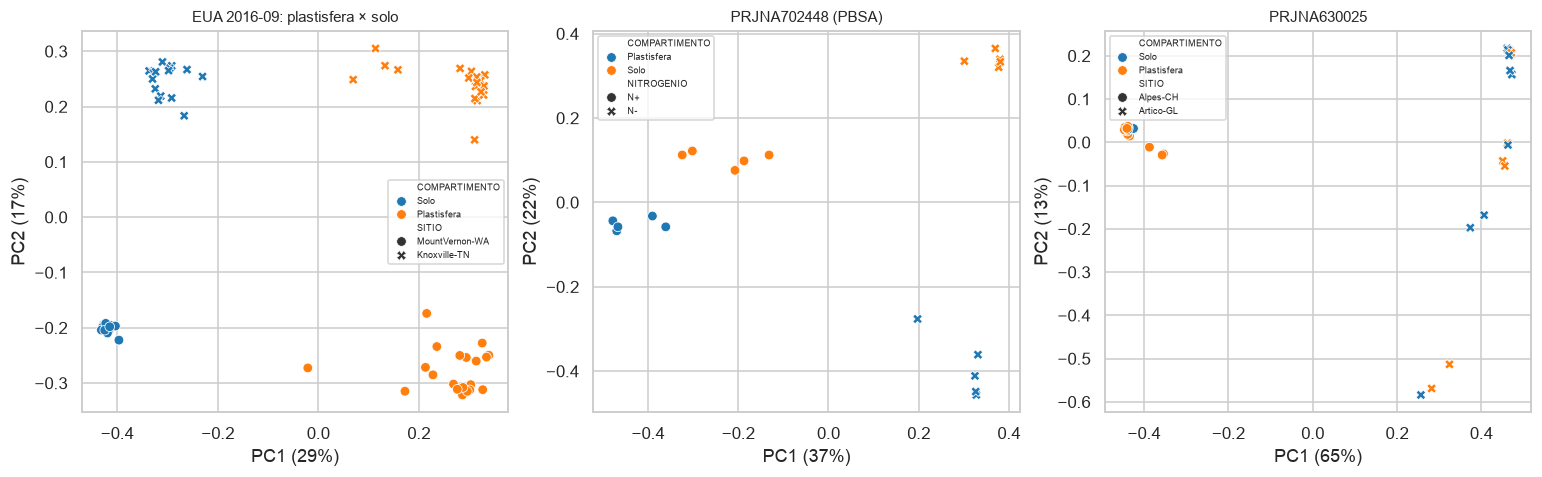

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
s = S("(BIOPROJECT=='PRJNA631499' and COMPARTIMENTO=='Plastisfera') or (BIOPROJECT=='PRJNA564156' and COLETA=='2016-09' and POLYMER in @filmes)")
pcoa_plot(s, 'COMPARTIMENTO', 'SITIO', axes[0], 'EUA 2016-09: plastisfera × solo')
s = S("BIOPROJECT=='PRJNA702448' and POLYMER=='PBSA'"); pcoa_plot(s, 'COMPARTIMENTO', 'NITROGENIO', axes[1], 'PRJNA702448 (PBSA)')
s = S("BIOPROJECT=='PRJNA630025'"); pcoa_plot(s, 'COMPARTIMENTO', 'SITIO', axes[2], 'PRJNA630025')
savefig('C1_pcoa')

## C2. Plastisfera: o polímero define a comunidade? (PRJNA631499, campo, 5 filmes × 2 sítios)

,gl,R2,F,p
SITIO,1.0,0.351,24.281,0.001
POLYMER,4.0,0.157,2.711,0.001
Residual,34.0,0.492,NaN,NaN


Gêneros que diferem PE × biodegradáveis nos 2 sítios (mesmo sentido): 9


,Plastisfera PE × biodegradáveis | Knoxville-TN,Plastisfera PE × biodegradáveis | MountVernon-WA,media
LABEL,,,
Klenkia,-3.90,-2.01,-2.96
LWQ8,-3.11,-2.76,-2.94
Methylobacterium-Methylorubrum,-2.57,-3.20,-2.89
Oxalobacteraceae (NC),-2.98,-2.74,-2.86
Deinococcus,-3.06,-2.44,-2.75
Nakamurella,-2.96,-2.17,-2.56
Sphingomonadaceae (NC),-2.43,-1.82,-2.13
Intrasporangiaceae (NC),-1.69,-1.54,-1.61
Marmoricola,-1.62,-1.28,-1.45


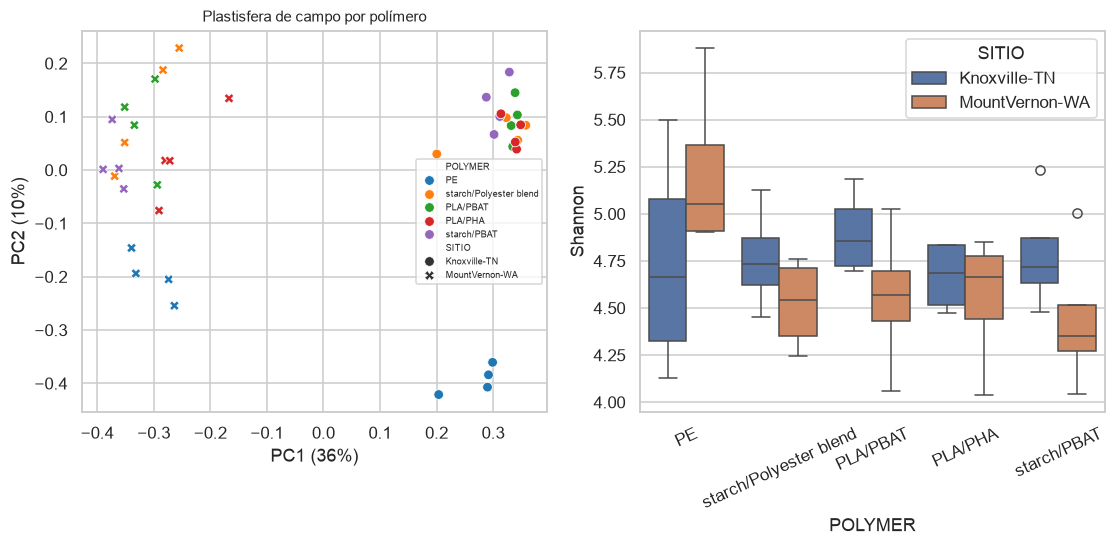

In [5]:
s = S("BIOPROJECT=='PRJNA631499' and COMPARTIMENTO=='Plastisfera'"); mm = meta.loc[s]
D = dist(rare, s).data
c2 = permanova(D, mm, ['SITIO', 'POLYMER'], strata=mm.SITIO.values); display(c2.round(3))
for sitio in ['Knoxville-TN', 'MountVernon-WA']:
    a = S(f"BIOPROJECT=='PRJNA631499' and COMPARTIMENTO=='Plastisfera' and SITIO=='{sitio}' and POLYMER=='PE'")
    b = S(f"BIOPROJECT=='PRJNA631499' and COMPARTIMENTO=='Plastisfera' and SITIO=='{sitio}' and POLYMER!='PE'")
    registra('C2', f'Plastisfera PE × biodegradáveis | {sitio}', a, b)
w = pd.concat({k[1]: v for k, v in DA_TAB.items() if k[0] == 'C2'}, axis=1)
cons = w.xs('dCLR', axis=1, level=1)[(w.xs('q', axis=1, level=1) < .05).all(1)]
cons = cons[(np.sign(cons).nunique(axis=1) == 1)].assign(media=lambda d: d.mean(1)).sort_values('media')
print(f'Gêneros que diferem PE × biodegradáveis nos 2 sítios (mesmo sentido): {len(cons)}')
cons.round(2).to_csv(TAB / 'C2_PE_vs_biodeg_plastisfera.csv')
display((cons if len(cons) <= 20 else pd.concat([cons.head(10), cons.tail(10)])).round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
pcoa_plot(s, 'POLYMER', 'SITIO', ax[0], 'Plastisfera de campo por polímero')
sns.boxplot(data=A.loc[s], x='POLYMER', y='Shannon', hue='SITIO', ax=ax[1]); ax[1].tick_params(axis='x', rotation=25)
savefig('C2_plastisfera_polimero')

## C3. Cultura de enriquecimento em laboratório × plastisfera de campo (PRJNA631499, Knoxville)
Mesmos filmes; a comunidade enriquecida em laboratório (3 e 6 semanas) é comparada com a plastisfera de campo de Knoxville (2016‑09).

,gl,R2,F,p
INCUBACAO_SEMANAS,1.0,0.013,0.711,0.737
POLYMER,3.0,0.216,3.832,0.001
Residual,41.0,0.771,NaN,NaN


Mais enriquecidos na cultura:


,dCLR,p,q,Phylum
LABEL,,,,
Afipia,7.53,0.0,0.0,Proteobacteria
Sphingopyxis,7.32,0.0,0.0,Proteobacteria
Camelimonas,7.20,0.0,0.0,Proteobacteria
Rhodanobacter,6.18,0.0,0.0,Proteobacteria
OLB14,6.16,0.0,0.0,Chloroflexi
Pseudaminobacter,5.93,0.0,0.0,Proteobacteria
Parapedobacter,5.78,0.0,0.0,Bacteroidota
Nocardia,5.62,0.0,0.0,Actinobacteriota
Mesorhizobium,5.57,0.0,0.0,Proteobacteria


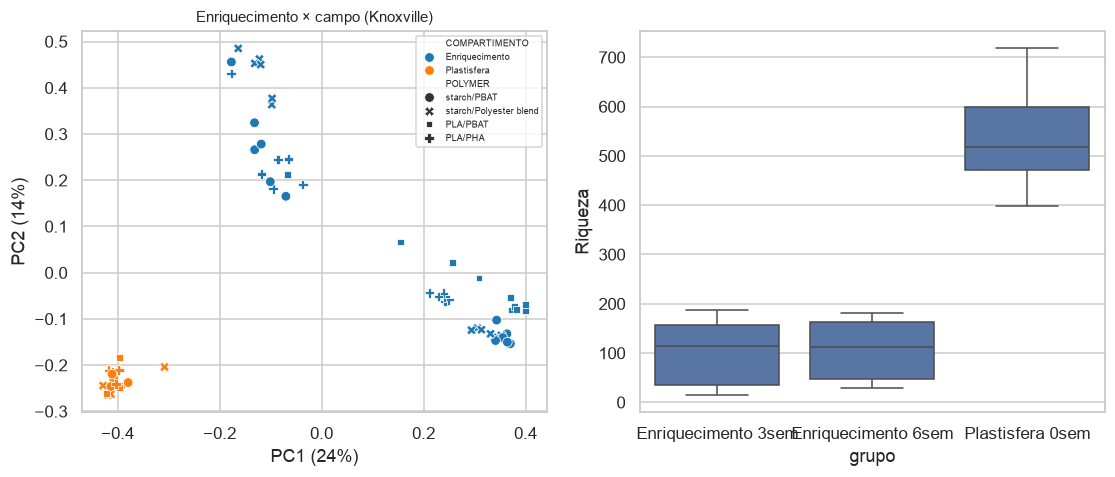

In [6]:
a = S("COMPARTIMENTO=='Enriquecimento'")
b = S("BIOPROJECT=='PRJNA631499' and COMPARTIMENTO=='Plastisfera' and SITIO=='Knoxville-TN' and POLYMER!='PE'")
registra('C3', 'Enriquecimento lab × plastisfera campo (Knoxville)', a, b)
a3 = S("COMPARTIMENTO=='Enriquecimento' and INCUBACAO_SEMANAS==6"); b3 = S("COMPARTIMENTO=='Enriquecimento' and INCUBACAO_SEMANAS==3")
registra('C3', 'Enriquecimento 6 × 3 semanas', a3, b3)
mm = meta.loc[a]; c3 = permanova(dist(rare, a).data, mm, ['INCUBACAO_SEMANAS', 'POLYMER']); display(c3.round(3))
d = DA_TAB[('C3', 'Enriquecimento lab × plastisfera campo (Knoxville)')].join(tax.drop_duplicates('LABEL').set_index('LABEL')[['Phylum']])
print('Mais enriquecidos na cultura:'); display(d[d.q < .05].sort_values('dCLR', ascending=False).head(15).round(2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
s = a + b; pcoa_plot(s, 'COMPARTIMENTO', 'POLYMER', ax[0], 'Enriquecimento × campo (Knoxville)')
sns.boxplot(data=A.loc[s].assign(grupo=lambda x: x.COMPARTIMENTO + ' ' + x.INCUBACAO_SEMANAS.fillna(0).astype(int).astype(str) + 'sem'),
            x='grupo', y='Riqueza', ax=ax[1]); savefig('C3_enriquecimento')

## C4. Mulch biodegradável × PE × papel × sem mulch no solo ao longo de 2 anos (PRJNA564156)
7 tratamentos (5 filmes, papel, sem mulch) × 2 sítios (TN, WA) × 4 coletas (2015‑05 a 2016‑09).

In [7]:
rows = []
for sitio in ['Knoxville-TN', 'MountVernon-WA']:
    s = S(f"BIOPROJECT=='PRJNA564156' and SITIO=='{sitio}'"); mm = meta.loc[s]
    r = permanova(dist(rare, s).data, mm, ['COLETA', 'POLYMER'], strata=mm.COLETA.values)
    rows.append(dict(sitio=sitio, R2_coleta=r.at['COLETA', 'R2'], R2_polimero=r.at['POLYMER', 'R2'], p_polimero=r.at['POLYMER', 'p']))
    for grupo, alvo in [('Biodegradáveis', filmes[:4]), ('PE', ['PE']), ('Papel', ['Papel'])]:
        a = S(f"BIOPROJECT=='PRJNA564156' and SITIO=='{sitio}' and POLYMER in @alvo")
        b = S(f"BIOPROJECT=='PRJNA564156' and SITIO=='{sitio}' and POLYMER=='Controle'")
        registra('C4', f'{grupo} × sem mulch | {sitio}', a, b, strata=None, extra_terms=('COLETA',))
display(pd.DataFrame(rows).round(3))

,sitio,R2_coleta,R2_polimero,p_polimero
0,Knoxville-TN,0.171,0.135,0.001
1,MountVernon-WA,0.274,0.090,0.001


,sitio,coleta,R2_polimero,p,g_Shannon_biodeg_vs_ctrl
0,Knoxville-TN,2015-05,0.262,0.819,0.232
1,Knoxville-TN,2015-09,0.312,0.325,-0.029
2,Knoxville-TN,2016-05,0.270,0.716,0.442
3,Knoxville-TN,2016-09,0.322,0.277,-0.288
4,MountVernon-WA,2015-05,0.282,0.879,-0.330
5,MountVernon-WA,2015-09,0.368,0.007,-0.953
6,MountVernon-WA,2016-05,0.289,0.748,-0.503
7,MountVernon-WA,2016-09,0.352,0.005,0.216


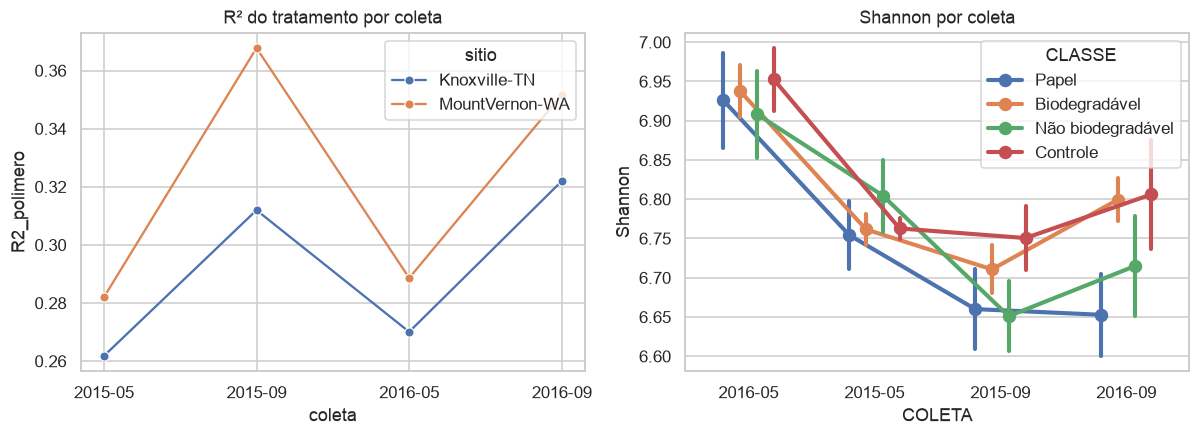

In [8]:
# trajetória: R² do polímero (vs sem mulch) em cada coleta
rows = []
for (sitio, col), mm in meta[meta.BIOPROJECT == 'PRJNA564156'].groupby(['SITIO', 'COLETA']):
    s = list(mm.index); r = permanova(dist(rare, s).data, mm, ['POLYMER'])
    g, _ = hedges_g(A.loc[mm.index[mm.CLASSE == 'Biodegradável'], 'Shannon'], A.loc[mm.index[mm.CLASSE == 'Controle'], 'Shannon'])
    rows.append(dict(sitio=sitio, coleta=col, R2_polimero=r.at['POLYMER', 'R2'], p=r.at['POLYMER', 'p'], g_Shannon_biodeg_vs_ctrl=g))
T = pd.DataFrame(rows); T.round(3).to_csv(TAB / 'C4_trajetoria.csv', index=False); display(T.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=T, x='coleta', y='R2_polimero', hue='sitio', marker='o', ax=ax[0]); ax[0].set_title('R² do tratamento por coleta')
d = A[A.BIOPROJECT == 'PRJNA564156']
sns.pointplot(data=d, x='COLETA', y='Shannon', hue='CLASSE', dodge=.4, ax=ax[1], errorbar='se'); ax[1].set_title('Shannon por coleta')
savefig('C4_mulch_tempo')

## C5. Microplástico × glifosato no solo e no intestino de *Enchytraeus crypticus* (PRJNA1155845)

,gl,R2,F,p
COMPARTIMENTO,1.0,0.434,53.145,0.001
POLYMER,2.0,0.203,12.411,0.001
GLIFOSATO,1.0,0.013,1.553,0.175
Residual,43.0,0.351,NaN,NaN


Solo                       Intestino                     
             gl     R2       F      p        gl     R2      F      p
GLIFOSATO   1.0  0.020   2.963  0.050       1.0  0.044  1.830  0.079
POLYMER     2.0  0.825  61.068  0.001       2.0  0.421  8.836  0.001
PxG         2.0  0.033   2.478  0.082       2.0  0.106  2.224  0.025
Residual   18.0  0.122     NaN    NaN      18.0  0.429    NaN    NaN

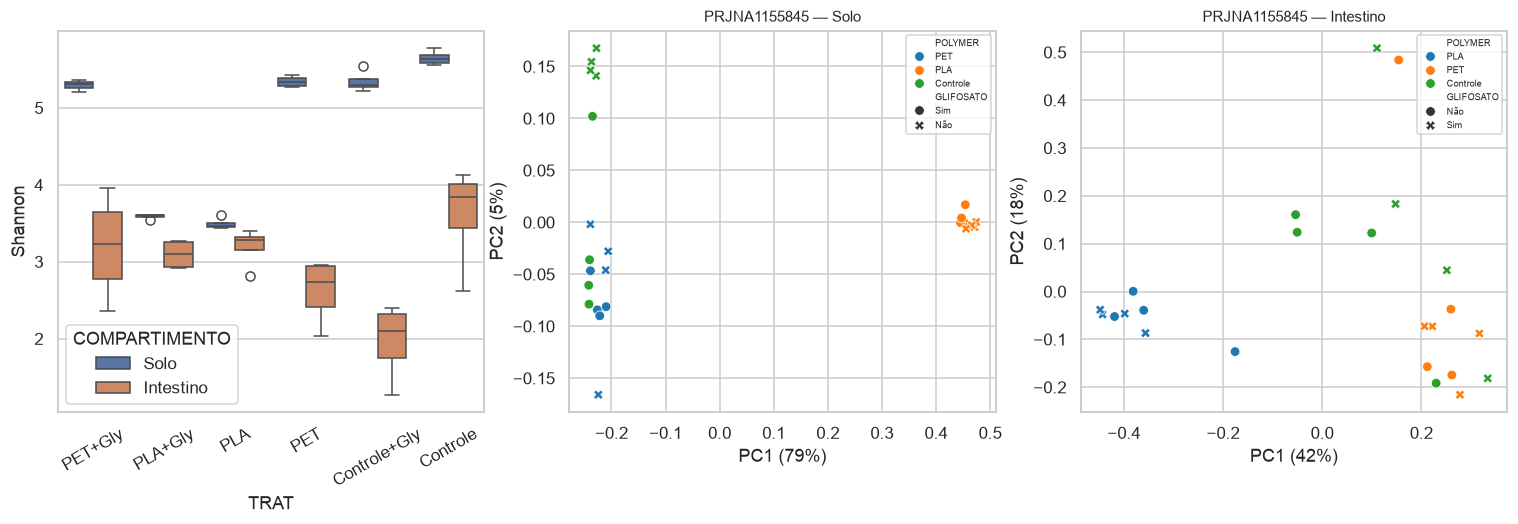

In [9]:
s = S("BIOPROJECT=='PRJNA1155845'"); mm = meta.loc[s].copy(); mm['PxG'] = mm.POLYMER + ':' + mm.GLIFOSATO
display(permanova(dist(rare, s).data, mm, ['COMPARTIMENTO', 'POLYMER', 'GLIFOSATO']).round(3))
tabs = {}
for comp in ['Solo', 'Intestino']:
    ss = S(f"BIOPROJECT=='PRJNA1155845' and COMPARTIMENTO=='{comp}'"); m2 = mm.loc[ss]
    tabs[comp] = permanova(dist(rare, ss).data, m2, ['GLIFOSATO', 'POLYMER', 'PxG'])
    for pol in ['PLA', 'PET']:
        a = S(f"BIOPROJECT=='PRJNA1155845' and COMPARTIMENTO=='{comp}' and POLYMER=='{pol}'")
        b = S(f"BIOPROJECT=='PRJNA1155845' and COMPARTIMENTO=='{comp}' and POLYMER=='Controle'")
        registra('C5', f'{pol} × controle | {comp} E. crypticus' if comp == 'Intestino' else f'{pol} × controle | solo (microcosmo)', a, b, extra_terms=('GLIFOSATO',))
    a = S(f"BIOPROJECT=='PRJNA1155845' and COMPARTIMENTO=='{comp}' and GLIFOSATO=='Sim'")
    b = S(f"BIOPROJECT=='PRJNA1155845' and COMPARTIMENTO=='{comp}' and GLIFOSATO=='Não'")
    registra('C5', f'Glifosato | {comp}', a, b, extra_terms=('POLYMER',))
display(pd.concat(tabs, axis=1).round(3))
d = A.loc[s].assign(TRAT=lambda x: x.POLYMER + np.where(x.GLIFOSATO == 'Sim', '+Gly', ''))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=d, x='TRAT', y='Shannon', hue='COMPARTIMENTO', ax=ax[0]); ax[0].tick_params(axis='x', rotation=30)
for a_, comp in zip(ax[1:], ['Solo', 'Intestino']):
    pcoa_plot(S(f"BIOPROJECT=='PRJNA1155845' and COMPARTIMENTO=='{comp}'"), 'POLYMER', 'GLIFOSATO', a_, f'PRJNA1155845 — {comp}')
savefig('C5_glifosato_intestino')

## C6. O plástico muda a rizosfera? (PRJNA1054347 milho; PRJEB59875 plantas de duna)

,gl,R2,F,p
COMPARTIMENTO,1.0,0.111,5.006,0.001
POLYMER,2.0,0.158,3.571,0.001
FxP,2.0,0.069,1.561,0.015
Residual,30.0,0.663,NaN,NaN


,gl,R2,F,p
CULTIVAR,1.0,0.089,2.359,0.001
POLYMER,2.0,0.104,1.374,0.053
PxP,1.0,0.048,1.255,0.163
Residual,20.0,0.759,NaN,NaN


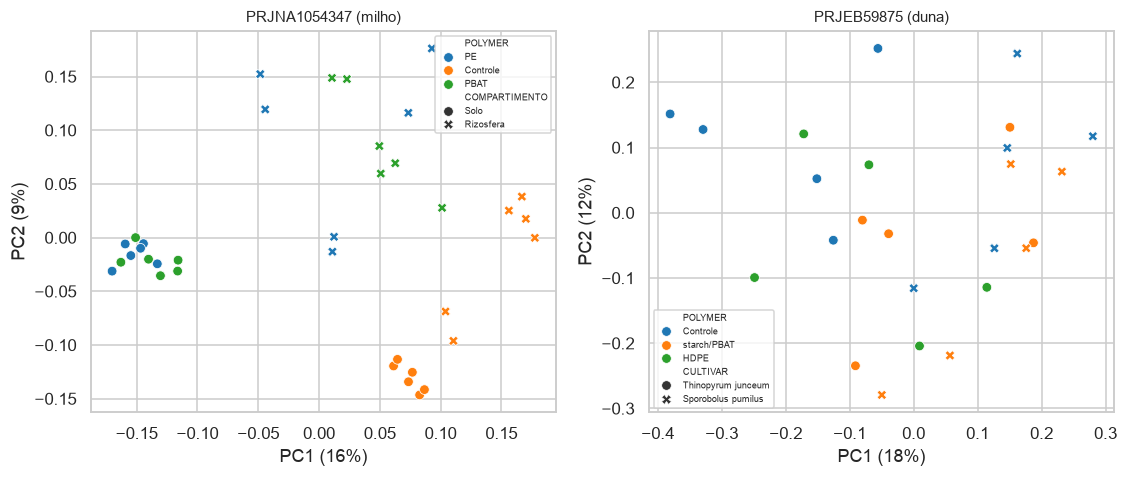

In [10]:
s = S("BIOPROJECT=='PRJNA1054347'"); mm = meta.loc[s].copy(); mm['FxP'] = mm.COMPARTIMENTO + ':' + mm.POLYMER
display(permanova(dist(rare, s).data, mm, ['COMPARTIMENTO', 'POLYMER', 'FxP']).round(3))
for comp in ['Solo', 'Rizosfera']:
    for pol in ['PE', 'PBAT']:
        a = S(f"BIOPROJECT=='PRJNA1054347' and COMPARTIMENTO=='{comp}' and POLYMER=='{pol}'")
        b = S(f"BIOPROJECT=='PRJNA1054347' and COMPARTIMENTO=='{comp}' and POLYMER=='Controle'")
        registra('C6', f'Milho {pol} × sem filme | {comp}', a, b)
s2 = S("BIOPROJECT=='PRJEB59875'"); m2 = meta.loc[s2].copy(); m2['PxP'] = m2.CULTIVAR + ':' + m2.POLYMER
display(permanova(dist(rare, s2).data, m2, ['CULTIVAR', 'POLYMER', 'PxP']).round(3))
for pl in ['Thinopyrum junceum', 'Sporobolus pumilus']:
    a = S(f"BIOPROJECT=='PRJEB59875' and CULTIVAR=='{pl}' and POLYMER!='Controle'")
    b = S(f"BIOPROJECT=='PRJEB59875' and CULTIVAR=='{pl}' and POLYMER=='Controle'")
    registra('C6', f'Duna: sacola × controle | rizosfera {pl}', a, b)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
pcoa_plot(s, 'POLYMER', 'COMPARTIMENTO', ax[0], 'PRJNA1054347 (milho)'); pcoa_plot(s2, 'POLYMER', 'CULTIVAR', ax[1], 'PRJEB59875 (duna)')
savefig('C6_rizosfera')

## C7. Fotoenvelhecimento, dose e tempo de microplástico (PRJNA1021161)

,gl,R2,F,p
DIAS,1.0,0.022,1.657,0.020
DOSE,1.0,0.017,1.244,0.207
ENVELHECIMENTO,2.0,0.051,1.878,0.013
Residual,67.0,0.910,NaN,NaN


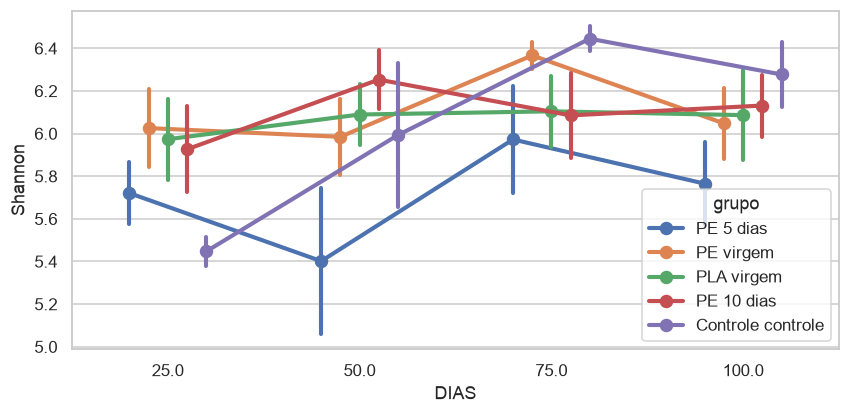

In [11]:
s = S("BIOPROJECT=='PRJNA1021161' and POLYMER=='PE'"); mm = meta.loc[s]
display(permanova(dist(rare, s).data, mm, ['DIAS', 'DOSE', 'ENVELHECIMENTO'], strata=mm.DIAS.values).round(3))
for env in ['5 dias', '10 dias']:
    a = S(f"BIOPROJECT=='PRJNA1021161' and POLYMER=='PE' and ENVELHECIMENTO=='{env}'")
    b = S("BIOPROJECT=='PRJNA1021161' and POLYMER=='PE' and ENVELHECIMENTO=='virgem'")
    registra('C7', f'PE fotoenvelhecido {env} × virgem', a, b, extra_terms=('DIAS',))
for pol in ['PE', 'PLA']:
    a = S(f"BIOPROJECT=='PRJNA1021161' and POLYMER=='{pol}' and ENVELHECIMENTO=='virgem'")
    b = S("BIOPROJECT=='PRJNA1021161' and POLYMER=='Controle' and DIAS>0")
    registra('C7', f'{pol} virgem × controle (PRJNA1021161)', a, b, extra_terms=('DIAS',))
d = A[A.BIOPROJECT == 'PRJNA1021161'].assign(grupo=lambda x: x.POLYMER + ' ' + x.ENVELHECIMENTO)
fig, ax = plt.subplots(figsize=(9, 4)); sns.pointplot(data=d[d.DIAS > 0], x='DIAS', y='Shannon', hue='grupo', dodge=.4, ax=ax, errorbar='se')
savefig('C7_envelhecimento')

## C8. PBSA × adubação nitrogenada (PRJNA702448)

In [12]:
s = S("BIOPROJECT=='PRJNA702448' and COMPARTIMENTO=='Solo' and TIPO_AMOSTRA!='Solo inicial (T0)'"); mm = meta.loc[s].copy()
mm['NxP'] = mm.NITROGENIO + ':' + mm.TRAT
display(permanova(dist(rare, s).data, mm, ['NITROGENIO', 'TRAT', 'NxP']).round(3))
for nitro in ['N-', 'N+']:
    a = S(f"BIOPROJECT=='PRJNA702448' and COMPARTIMENTO=='Solo' and POLYMER=='PBSA' and NITROGENIO=='{nitro}'")
    b = S(f"BIOPROJECT=='PRJNA702448' and COMPARTIMENTO=='Solo' and POLYMER=='Controle' and NITROGENIO=='{nitro}' and TIPO_AMOSTRA!='Solo inicial (T0)'")
    registra('C8', f'PBSA × controle no solo | {nitro}', a, b)
a = S("BIOPROJECT=='PRJNA702448' and COMPARTIMENTO=='Plastisfera' and NITROGENIO=='N+'"); b = S("BIOPROJECT=='PRJNA702448' and COMPARTIMENTO=='Plastisfera' and NITROGENIO=='N-'")
_ = registra('C8', 'N+ × N- na plastisfera do PBSA', a, b)
print(pd.DataFrame([r for r in RES if r['id'] == 'C8']).set_index('contraste').round(3).T)

,gl,R2,F,p
NITROGENIO,1.0,0.293,13.479,0.001
TRAT,1.0,0.192,8.823,0.001
NxP,1.0,0.167,7.662,0.001
Residual,16.0,0.348,NaN,NaN


contraste          PBSA × controle no solo | N- PBSA × controle no solo | N+  \
n_A                                           5                            5   
n_B                                           5                            5   
R2                                        0.323                        0.593   
p_perm                                    0.011                        0.011   
g_Shannon                                -0.641                       -3.347   
g_Riqueza                                -0.693                      -11.231   
pct_Riqueza                              -1.685                      -63.602   
n_generos_q05                                 0                           99   
n_generos_testados                          345                          351   
p_disp                                    0.009                        0.009   
id                                           C8                           C8   

contraste          N+ × N- na plastisfe

## C9. Assinatura global biodegradável × convencional × controle no solo (entre estudos)
Resultado do notebook principal (meta‑análise e modelo misto em 8 estratos projeto × fração). Aqui: contraste direto
**biodegradável × não biodegradável** dentro de cada estudo que tem os dois.

In [13]:
rows = []
for pj, mm in meta[meta.COMPARTIMENTO.isin(['Solo', 'Rizosfera'])].groupby('ESTRATO'):
    a = list(mm.index[mm.CLASSE == 'Biodegradável']); b = list(mm.index[mm.CLASSE == 'Não biodegradável'])
    if len(a) >= 3 and len(b) >= 3:
        r, d = registra('C9', f'Biodegradável × não biodeg. | {pj}', a, b)
c9 = pd.DataFrame([r for r in RES if r['id'] == 'C9']).set_index('contraste'); display(c9.round(3))
mu, se, p, I2 = dersimonian_laird(c9.g_Shannon, (c9.n_A + c9.n_B) / (c9.n_A * c9.n_B) + c9.g_Shannon ** 2 / (2 * (c9.n_A + c9.n_B)))
print(f'Meta-análise Shannon biodegradável − não biodeg.: g = {mu:.2f} ± {1.96*se:.2f}, p = {p:.3f}, I² = {I2:.0%}, k = {len(c9)}')

,n_A,n_B,R2,p_perm,g_Shannon,g_Riqueza,pct_Riqueza,n_generos_q05,n_generos_testados,p_disp,id
contraste,,,,,,,,,,,
Biodegradável × não biodeg. | PRJEB59875 | Rhizosphere,10,5,0.103,0.045,0.385,0.012,-1.083,0,545,0.540,C9
Biodegradável × não biodeg. | PRJNA1021161 | Bulk,24,72,0.014,0.150,0.185,0.205,7.014,0,710,0.648,C9
Biodegradável × não biodeg. | PRJNA1054347 | Bulk,6,6,0.168,0.002,0.142,0.519,0.535,0,444,0.423,C9
Biodegradável × não biodeg. | PRJNA1054347 | Rhizosphere,6,6,0.109,0.141,0.466,0.522,2.351,0,436,0.037,C9
Biodegradável × não biodeg. | PRJNA1155845 | Bulk,8,8,0.866,0.001,-23.194,-14.491,-63.329,156,292,0.001,C9
Biodegradável × não biodeg. | PRJNA564156 | Bulk,96,24,0.005,0.674,0.204,0.206,1.589,0,494,0.546,C9
Biodegradável × não biodeg. | PRJNA630025 | Bulk,13,4,0.082,0.235,-0.191,0.054,5.913,0,258,0.113,C9
Biodegradável × não biodeg. | PRJNA932786 | Bulk,4,4,0.134,0.748,-0.013,-0.410,-3.330,0,547,0.386,C9


Meta-análise Shannon biodegradável − não biodeg.: g = -0.00 ± 0.72, p = 0.996, I² = 79%, k = 8


## C10. Guilda de nitrificantes e ciclo do N

                Nitrificantes_%  Patescibacteria_%
COMPARTIMENTO                                     
Enriquecimento             0.00               0.00
Intestino                  0.00               0.05
Plastisfera                0.02              13.28
Rizosfera                  2.06               1.26
Solo                       1.20               1.50


,Nitrospira,Nitrosospira,MND1,Ellin6067
desenho,,,,
Plastisfera × solo | EUA Knoxville-TN,-4.05,-2.29,-4.63,-4.50
Plastisfera × solo | EUA MountVernon-WA,-3.67,-2.56,-3.82,-2.23
Plastisfera × solo | PBSA DE N-,-3.76,-2.11,-5.31,-4.46
Plastisfera × solo | PBSA DE N+,-1.10,-0.43,-1.40,-0.52
Plastisfera × solo | Alpes-CH,-0.49,NaN,NaN,-0.36
Plastisfera × solo | Artico-GL,-0.15,NaN,-0.25,-0.19


Nitrificantes no solo bulk, plástico − controle: g = 0.32 ± 0.86, p = 0.471, I² = 86%, k = 6


,estrato,g,v
0,PRJNA1021161 | Bulk,0.29,0.08
1,PRJNA1054347 | Bulk,4.22,0.75
2,PRJNA1155845 | Bulk,-1.04,0.21
3,PRJNA564156 | Bulk,0.55,0.05
4,PRJNA702448 | Bulk,-0.52,0.20
5,PRJNA932786 | Bulk,-0.47,0.38


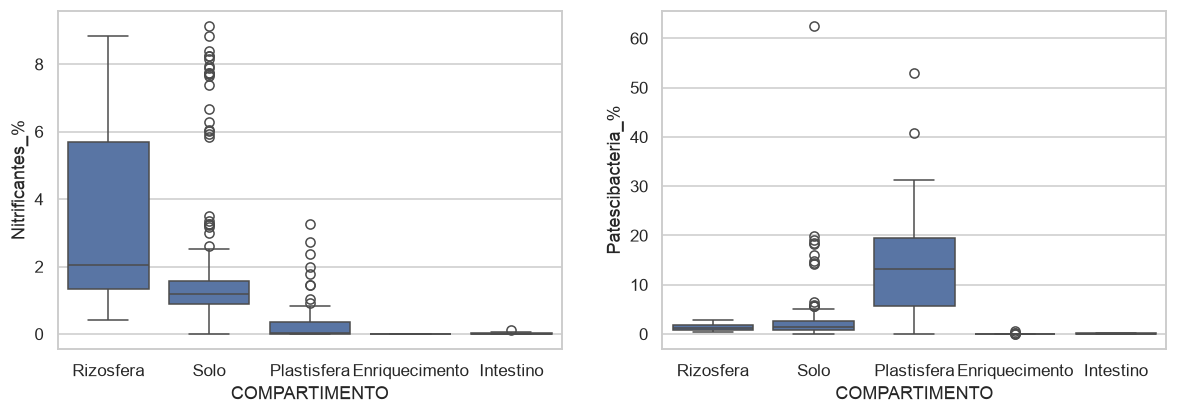

In [14]:
nitrif = ['Nitrospira', 'Nitrosospira', 'Nitrosomonas', 'MND1', 'Ellin6067', 'Nitrosomonadaceae (NC)', 'IS-44']
rel = rare / rare.sum()
lab = tax.reindex(rel.index).LABEL
A['Nitrificantes_%'] = rel[lab.isin(nitrif)].sum() * 100
A['Patescibacteria_%'] = rel[tax.reindex(rel.index).Phylum.eq('Patescibacteria')].sum() * 100
print(A.groupby(['COMPARTIMENTO'])[['Nitrificantes_%', 'Patescibacteria_%']].median().round(2))
rows = []
for r in [x for x in RES if x['id'] == 'C1']:
    k = r['contraste']; d = DA_TAB[('C1', k)]
    rows.append({'desenho': k, **{g: d.dCLR.get(g, np.nan) for g in ['Nitrospira', 'Nitrosospira', 'MND1', 'Ellin6067']}})
display(pd.DataFrame(rows).set_index('desenho').round(2))
# no solo bulk: plástico × controle por estrato
rows = []
for pj, mm in meta[meta.COMPARTIMENTO.eq('Solo')].groupby('ESTRATO'):
    a = mm.index[mm.TRAT == 'Plástico']; b = mm.index[mm.TRAT == 'Controle']
    if len(a) >= 3 and len(b) >= 3:
        g, v = hedges_g(A.loc[a, 'Nitrificantes_%'], A.loc[b, 'Nitrificantes_%']); rows.append(dict(estrato=pj, g=g, v=v))
e = pd.DataFrame(rows); mu, se, p, I2 = dersimonian_laird(e.g, e.v)
print(f'Nitrificantes no solo bulk, plástico − controle: g = {mu:.2f} ± {1.96*se:.2f}, p = {p:.3f}, I² = {I2:.0%}, k = {len(e)}')
display(e.round(2))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=A, x='COMPARTIMENTO', y='Nitrificantes_%', ax=ax[0]); sns.boxplot(data=A, x='COMPARTIMENTO', y='Patescibacteria_%', ax=ax[1])
savefig('C10_nitrificantes_patescibacteria')

## C11. Patescibacteria (CPR) na plastisfera

In [15]:
# refaz os grupos do C1 para testar a % de Patescibacteria
grupos = {
 'EUA Knoxville-TN': (S("BIOPROJECT=='PRJNA631499' and COMPARTIMENTO=='Plastisfera' and SITIO=='Knoxville-TN'"), S("BIOPROJECT=='PRJNA564156' and COLETA=='2016-09' and SITIO=='Knoxville-TN' and POLYMER in @filmes")),
 'EUA MountVernon-WA': (S("BIOPROJECT=='PRJNA631499' and COMPARTIMENTO=='Plastisfera' and SITIO=='MountVernon-WA'"), S("BIOPROJECT=='PRJNA564156' and COLETA=='2016-09' and SITIO=='MountVernon-WA' and POLYMER in @filmes")),
 'PBSA DE': (S("BIOPROJECT=='PRJNA702448' and COMPARTIMENTO=='Plastisfera'"), S("BIOPROJECT=='PRJNA702448' and COMPARTIMENTO=='Solo' and POLYMER=='PBSA'")),
 'Alpes-CH': (S("BIOPROJECT=='PRJNA630025' and COMPARTIMENTO=='Plastisfera' and SITIO=='Alpes-CH'"), S("BIOPROJECT=='PRJNA630025' and COMPARTIMENTO=='Solo' and SITIO=='Alpes-CH'")),
 'Artico-GL': (S("BIOPROJECT=='PRJNA630025' and COMPARTIMENTO=='Plastisfera' and SITIO=='Artico-GL'"), S("BIOPROJECT=='PRJNA630025' and COMPARTIMENTO=='Solo' and SITIO=='Artico-GL'")),
 'Enriquecimento × campo TN': (S("COMPARTIMENTO=='Enriquecimento'"), S("BIOPROJECT=='PRJNA631499' and COMPARTIMENTO=='Plastisfera' and SITIO=='Knoxville-TN'")),
}
rows = []
for k, (a, b) in grupos.items():
    x, y = A.loc[a, 'Patescibacteria_%'], A.loc[b, 'Patescibacteria_%']
    rows.append(dict(desenho=k, plastisfera_mediana=x.median(), solo_mediana=y.median(), p=stats.mannwhitneyu(x, y).pvalue))
c11 = pd.DataFrame(rows).set_index('desenho'); c11.round(4).to_csv(TAB / 'C11_patescibacteria.csv'); display(c11.round(3))
top_cpr = (rel[tax.reindex(rel.index).Phylum.eq('Patescibacteria')].groupby(tax.reindex(rel.index).Class).sum()
           .T.groupby(A.COMPARTIMENTO).mean().T * 100).round(2)
display(top_cpr.sort_values('Plastisfera', ascending=False).head(8))

,plastisfera_mediana,solo_mediana,p
desenho,,,
EUA Knoxville-TN,20.229,2.692,0.000
EUA MountVernon-WA,11.842,3.158,0.000
PBSA DE,0.000,0.017,0.096
Alpes-CH,16.342,18.275,0.860
Artico-GL,5.796,5.392,0.408
Enriquecimento × campo TN,0.000,20.229,0.000


COMPARTIMENTO,Enriquecimento,Intestino,Plastisfera,Rizosfera,Solo
Class,,,,,
Saccharimonadia,0.03,0.05,11.22,0.94,1.64
Parcubacteria,0.00,0.00,1.92,0.26,0.42
Gracilibacteria,0.00,0.00,0.24,0.01,0.04
Microgenomatia,0.00,0.00,0.06,0.03,0.02
ABY1,0.00,0.00,0.02,0.02,0.01
Berkelbacteria,0.00,0.00,0.01,0.00,0.05
CPR2,0.00,0.00,0.00,0.00,0.00
Kazania,0.00,0.00,0.00,0.00,0.00


## C12. Formato e dose como moderadores do efeito do plástico (meta‑regressão entre estudos)
Para cada estrato com controle: R² (PERMANOVA plástico × controle) e g de Shannon, relacionados ao formato (partícula × filme)
e ao tipo de experimento (microcosmo × campo).

In [16]:
rows = []
for pj, mm in meta[meta.COMPARTIMENTO.isin(['Solo', 'Rizosfera'])].groupby('ESTRATO'):
    a = list(mm.index[mm.TRAT == 'Plástico']); b = list(mm.index[mm.TRAT == 'Controle'])
    if len(a) >= 3 and len(b) >= 3:
        r, _ = resumo_contraste(pj, a, b, rare, alpha, gcounts, perms=199)
        rows.append(dict(estrato=pj, R2=r['R2'], p=r['p_perm'], g_Shannon=r['g_Shannon'],
                         formato=mm.POLYMER_FORMAT.dropna().mode().iloc[0] if mm.POLYMER_FORMAT.notna().any() else 'NA',
                         experimento=mm.EXPERIMENT_TYPE.mode().iloc[0]))
M12 = pd.DataFrame(rows).set_index('estrato'); display(M12.round(3))
print(M12.groupby('experimento')[['R2', 'g_Shannon']].median().round(3))
print(M12.groupby('formato')[['R2', 'g_Shannon']].median().round(3))
print('Mann-Whitney R2 Ex_situ vs In_situ: p =', round(stats.mannwhitneyu(*[g.R2 for _, g in M12.groupby('experimento')]).pvalue, 3))
M12.round(3).to_csv(TAB / 'C12_moderadores.csv')

,R2,p,g_Shannon,formato,experimento
estrato,,,,,
PRJEB59875 | Rhizosphere,0.057,0.085,1.046,Fragment,In_situ
PRJNA1021161 | Bulk,0.007,0.710,-0.032,Particle,Ex_situ
PRJNA1054347 | Bulk,0.226,0.005,1.718,NA,In_situ
PRJNA1054347 | Rhizosphere,0.128,0.005,0.521,NA,In_situ
PRJNA1155845 | Bulk,0.236,0.010,-1.344,Particle,Ex_situ
PRJNA564156 | Bulk,0.007,0.285,-0.143,Film,In_situ
PRJNA702448 | Bulk,0.190,0.005,-1.449,NA,Ex_situ
PRJNA932786 | Bulk,0.100,0.220,-0.047,Particle,Ex_situ


                R2  g_Shannon
experimento                  
Ex_situ      0.145     -0.695
In_situ      0.092      0.783
             R2  g_Shannon
formato                   
Film      0.007     -0.143
Fragment  0.057      1.046
NA        0.190      0.521
Particle  0.100     -0.047
Mann-Whitney R2 Ex_situ vs In_situ: p = 0.886


## 13. Tabela‑resumo de todos os contrastes

In [17]:
R = pd.DataFrame(RES)[['id', 'contraste', 'n_A', 'n_B', 'R2', 'p_perm', 'p_disp', 'g_Shannon', 'pct_Riqueza', 'n_generos_q05', 'n_generos_testados']]
R.round(3).to_csv(TAB / 'resumo_contrastes.csv', index=False)
pd.set_option('display.max_rows', 100); R.round(3)

,id,contraste,n_A,n_B,R2,p_perm,p_disp,g_Shannon,pct_Riqueza,n_generos_q05,n_generos_testados
0,C1,Plastisfera × solo | EUA Knoxville-TN,20,15,0.445,0.001,0.062,-7.982,-68.792,362,501
1,C1,Plastisfera × solo | EUA MountVernon-WA,20,15,0.552,0.001,0.000,-5.764,-60.444,376,484
2,C1,Plastisfera × solo | PBSA DE N-,5,5,0.570,0.011,0.076,-2.293,-38.286,147,396
3,C1,Plastisfera × solo | PBSA DE N+,5,5,0.326,0.031,0.602,-2.842,-86.159,47,217
4,C1,Plastisfera × solo | Alpes-CH,11,7,0.107,0.094,0.006,-0.125,3.148,0,216
5,C1,Plastisfera × solo | Artico-GL,8,10,0.051,0.388,0.328,-0.265,-4.261,0,199
6,C2,Plastisfera PE × biodegradáveis | Knoxville-TN,4,16,0.250,0.001,0.637,-0.110,44.552,142,385
7,C2,Plastisfera PE × biodegradáveis | MountVernon-WA,4,16,0.148,0.001,0.299,1.923,43.416,25,396
8,C3,Enriquecimento lab × plastisfera campo (Knoxvi...,46,16,0.198,0.001,0.000,-2.592,-78.496,131,187
9,C3,Enriquecimento 6 × 3 semanas,24,22,0.013,0.881,0.416,0.297,-1.762,1,99


In [18]:
agg = R.groupby('id').agg(n_contrastes=('contraste', 'size'), n_amostras=('n_A', lambda s: int(s.sum() + R.loc[s.index, 'n_B'].sum())),
                          R2_mediano=('R2', 'median'), frac_sig=('p_perm', lambda p: (p < .05).mean()),
                          g_Shannon_mediano=('g_Shannon', 'median'), generos_DA_mediano=('n_generos_q05', 'median'))
agg.round(3).to_csv(TAB / 'resumo_por_comparacao.csv'); agg.round(3)

,n_contrastes,n_amostras,R2_mediano,frac_sig,g_Shannon_mediano,generos_DA_mediano
id,,,,,,
C1,6,126,0.386,0.667,-2.567,97.0
C2,2,40,0.199,1.000,0.907,83.5
C3,2,108,0.106,0.500,-1.147,66.0
C4,6,216,0.056,0.500,-0.382,0.0
C5,6,112,0.134,0.500,-0.318,7.5
C6,6,73,0.177,0.833,1.636,0.0
C7,4,168,0.017,0.250,0.017,0.0
C8,3,30,0.593,1.000,-3.347,65.0
C9,8,296,0.106,0.375,0.163,0.0


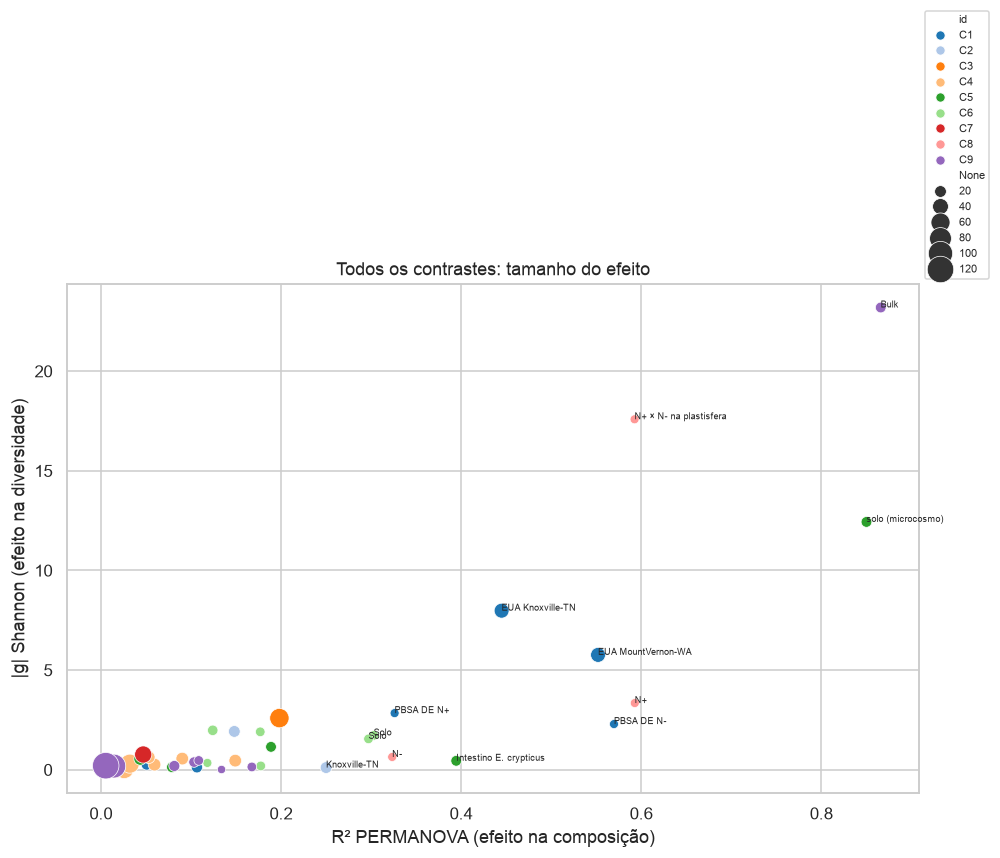

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=R, x='R2', y=R.g_Shannon.abs(), hue='id', size=R.n_A + R.n_B, sizes=(30, 300), ax=ax, palette='tab20')
for _, r in R[R.R2 > .25].iterrows(): ax.annotate(r.contraste.split('|')[-1].strip()[:22], (r.R2, abs(r.g_Shannon)), fontsize=6)
ax.set_xlabel('R² PERMANOVA (efeito na composição)'); ax.set_ylabel('|g| Shannon (efeito na diversidade)'); ax.legend(fontsize=7, bbox_to_anchor=(1, 1))
ax.set_title('Todos os contrastes: tamanho do efeito'); savefig('13_mapa_efeitos')